In [1]:
import gc
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)

from IPython.display import display

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_SPLITS = 5
TARGET = "status_penanganan"

In [2]:
from analysis_data import load_analysis_frame

analysis_frame = load_analysis_frame("train")
test_analysis_frame = load_analysis_frame("test")

train_df = (
    analysis_frame.to_pandas()
    if hasattr(analysis_frame, "to_pandas")
    else analysis_frame.copy()
)

test_df = (
    test_analysis_frame.to_pandas()
    if hasattr(test_analysis_frame, "to_pandas")
    else test_analysis_frame.copy()
)

if TARGET not in train_df.columns:
    raise ValueError(f"Kolom target {TARGET} tidak ditemukan.")

# Bebaskan RAM: frame polars tidak dipakai lagi setelah dikonversi
del analysis_frame, test_analysis_frame
gc.collect()

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df[TARGET] = train_df[TARGET].astype(str)

print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Jumlah kelas: {train_df[TARGET].nunique()}")
print("\nDistribusi target:")
display(
    train_df[TARGET]
    .value_counts()
    .rename_axis(TARGET)
    .to_frame("jumlah")
    .assign(
        persentase=lambda x: x["jumlah"] / len(train_df) * 100
    )
)

Train shape: (1243617, 164)
Test shape: (362245, 163)
Jumlah kelas: 7

Distribusi target:


,jumlah,persentase
status_penanganan,,
normal,473531,38.076916
konfirmasi_alamat,272911,21.944940
tertunda_operasional,185496,14.915846
gagal_antar_awal,124341,9.998336
retur_pengirim,87740,7.055227
rusak_perjalanan,61942,4.980794
klaim_hilang,37656,3.027942


In [3]:
train_features_available = set(train_df.columns) - {TARGET}
test_features_available = set(test_df.columns)

train_only_columns = sorted(
    train_features_available - test_features_available
)

test_only_columns = sorted(
    test_features_available - train_features_available
)

print("Kolom hanya di train:", train_only_columns)
print("Kolom hanya di test:", test_only_columns)

common_features = sorted(
    train_features_available.intersection(test_features_available)
)

print(f"Jumlah kolom yang sama: {len(common_features)}")

Kolom hanya di train: []
Kolom hanya di test: []
Jumlah kolom yang sama: 163


In [4]:
id_candidates = [
    "shipment_id",
    "id"
]

id_column = next(
    (col for col in id_candidates if col in test_df.columns),
    None
)

if id_column is not None:
    test_ids = test_df[id_column].copy()
else:
    test_ids = pd.Series(
        np.arange(len(test_df)),
        name="row_id"
    )

excluded_columns = {
    TARGET,
    "shipment_id"
}

feature_columns = [
    col for col in common_features
    if col not in excluded_columns
]

print(f"Kolom ID: {id_column}")
print(f"Jumlah kandidat fitur: {len(feature_columns)}")

Kolom ID: shipment_id
Jumlah kandidat fitur: 162


In [5]:
def is_claim_or_outcome_feature(column):
    name = column.lower()

    risky_terms = [
        "klaim",
        "claim",
        "refund",
        "retur",
        "return",
        "hilang",
        "loss",
        "rusak",
        "damage",
        "kompensasi",
        "compensation"
    ]

    return any(term in name for term in risky_terms)


def get_feature_scenario(columns, scenario):
    selected = []

    for col in columns:
        name = col.lower()

        if is_claim_or_outcome_feature(name):
            continue

        if name.startswith(("sc_", "rt_", "iv_")):
            if scenario == "A":
                continue

            if scenario == "B" and name.startswith("iv_"):
                continue

        if name.startswith("sc_"):
            unavailable_scan_terms = [
                "selesai",
                "terkirim",
                "gagal_antar",
                "attempt",
                "percobaan"
            ]

            if any(term in name for term in unavailable_scan_terms):
                continue

        selected.append(col)

    return selected


scenario_features = {
    "A": get_feature_scenario(feature_columns, "A"),
    "B": get_feature_scenario(feature_columns, "B"),
    "C": get_feature_scenario(feature_columns, "C")
}

scenario_summary = pd.DataFrame([
    {
        "scenario": scenario,
        "jumlah_fitur": len(columns),
        "fitur_scan": sum(col.lower().startswith("sc_") for col in columns),
        "fitur_route": sum(col.lower().startswith("rt_") for col in columns),
        "fitur_invoice": sum(col.lower().startswith("iv_") for col in columns)
    }
    for scenario, columns in scenario_features.items()
])

display(scenario_summary)

,scenario,jumlah_fitur,fitur_scan,fitur_route,fitur_invoice
0,A,95,0,0,0
1,B,142,20,27,0
2,C,159,20,27,17


In [6]:
all_scenario_features = set().union(
    *[set(cols) for cols in scenario_features.values()]
)

excluded_from_scenarios = sorted(
    set(feature_columns) - all_scenario_features
)

print(f"Jumlah fitur yang dikecualikan: {len(excluded_from_scenarios)}")
display(pd.DataFrame({
    "excluded_feature": excluded_from_scenarios
}))

Jumlah fitur yang dikecualikan: 3


,excluded_feature
0,iv_amount_klaim
1,iv_n_klaim
2,sc_n_selesai


In [7]:
SELECTED_SCENARIO = "B"

selected_features = scenario_features[SELECTED_SCENARIO]

if len(selected_features) == 0:
    raise ValueError("Tidak ada fitur yang tersedia pada skenario terpilih.")

X = train_df[selected_features].copy()
X_test = test_df[selected_features].copy()

y = train_df[TARGET].copy()

class_labels = sorted(y.unique().tolist())

print(f"Skenario: {SELECTED_SCENARIO}")
print(f"Jumlah fitur: {len(selected_features)}")
print(f"Jumlah kelas: {len(class_labels)}")

Skenario: B
Jumlah fitur: 142
Jumlah kelas: 7


In [8]:
entity_id_candidates = [
    "customer_id",
    "courier_id",
    "hub_id",
    "package_id",
    "promo_id"
]

entity_id_features = [
    col for col in entity_id_candidates
    if col in X.columns
]

numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

cardinality_summary = pd.DataFrame({
    "feature": X.columns,
    "dtype": X.dtypes.astype(str).values,
    "unique_count": [
        X[col].nunique(dropna=True)
        for col in X.columns
    ]
}).sort_values(
    "unique_count",
    ascending=False
)

display(cardinality_summary.head(30))

,feature,dtype,unique_count
102,rt_speed_mean,float32,1165442
109,sc_gap_std,float32,1131734
138,x_hub_load_duration,float32,994834
27,customer_id,str,508086
16,cust_credit_score,float32,469238
15,cust_complaint_index,float32,418551
77,r_volumetric_weight,float32,314794
135,x_distance_fragility,float32,275818
76,r_value_per_kg,float32,237810
78,rt_cost_mean,float32,78618


In [9]:
high_cardinality_features = [
    col for col in entity_id_features
    if X[col].nunique(dropna=True) > 100000
]

X = X.drop(columns=high_cardinality_features)
X_test = X_test.drop(columns=high_cardinality_features)

categorical_features = [
    col for col in X.columns
    if (
        col in entity_id_candidates
        or not pd.api.types.is_numeric_dtype(X[col])
        or pd.api.types.is_object_dtype(X[col])
        or isinstance(X[col].dtype, pd.CategoricalDtype)
        or pd.api.types.is_bool_dtype(X[col])
    )
]

for col in categorical_features:
    train_values = X[col].astype("string").fillna("__MISSING__")
    test_values = X_test[col].astype("string").fillna("__MISSING__")

    categories = pd.Index(
        pd.concat(
            [train_values, test_values],
            ignore_index=True
        ).unique()
    )

    X[col] = pd.Categorical(
        train_values,
        categories=categories
    )

    X_test[col] = pd.Categorical(
        test_values,
        categories=categories
    )

numeric_features = [
    col for col in X.columns
    if col not in categorical_features
]

for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")
    X_test[col] = pd.to_numeric(X_test[col], errors="coerce")

selected_features = X.columns.tolist()

print(f"Fitur akhir: {len(selected_features)}")
print(f"Fitur kategorikal: {len(categorical_features)}")
print(f"ID cardinality tinggi yang dikeluarkan: {high_cardinality_features}")

Fitur akhir: 141
Fitur kategorikal: 28
ID cardinality tinggi yang dikeluarkan: ['customer_id']


In [10]:
X = X.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

missing_summary = pd.DataFrame({
    "missing_train": X.isna().sum(),
    "missing_train_pct": X.isna().mean() * 100,
    "missing_test": X_test.isna().sum(),
    "missing_test_pct": X_test.isna().mean() * 100
}).sort_values(
    "missing_train_pct",
    ascending=False
)

display(missing_summary.head(30))

assert X.columns.tolist() == X_test.columns.tolist()
assert len(X) == len(y)
assert len(X_test) == len(test_ids)

,missing_train,missing_train_pct,missing_test,missing_test_pct
promo_bulan_akhir,1032408,83.016556,300502,82.955458
promo_bulan_mulai,1032408,83.016556,300502,82.955458
promo_diskon_persen,1032408,83.016556,300502,82.955458
volume_l,37012,2.976157,11013,3.040208
cust_credit_score,24920,2.003832,7308,2.017419
cour_courier_score,13378,1.075733,3884,1.072203
rt_speed_mean,8934,0.718388,2574,0.710569
rt_duration_mean,8934,0.718388,2574,0.710569
rt_duration_max,8934,0.718388,2574,0.710569
berat_volumetrik,0,0.000000,0,0.000000


In [11]:
class_counts = y.value_counts()

if class_counts.min() < N_SPLITS:
    raise ValueError("Jumlah data pada kelas terkecil tidak mencukupi untuk 5 fold.")

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

folds = list(skf.split(X, y))

for fold, (train_idx, valid_idx) in enumerate(folds, start=1):
    print(
        f"Fold {fold}: "
        f"train={len(train_idx):,}, "
        f"valid={len(valid_idx):,}"
    )

Fold 1: train=994,893, valid=248,724
Fold 2: train=994,893, valid=248,724
Fold 3: train=994,894, valid=248,723
Fold 4: train=994,894, valid=248,723
Fold 5: train=994,894, valid=248,723


In [12]:
lgb_params = {
    "objective": "multiclass",
    "n_estimators": 3000,
    "learning_rate": 0.05,
    "num_leaves": 63,
    "max_depth": -1,
    "min_child_samples": 100,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
    "verbosity": -1
}

print(json.dumps(lgb_params, indent=4))

{
    "objective": "multiclass",
    "n_estimators": 3000,
    "learning_rate": 0.05,
    "num_leaves": 63,
    "max_depth": -1,
    "min_child_samples": 100,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
}


In [13]:
oof_predictions = np.zeros(
    (len(X), len(class_labels)),
    dtype=np.float32
)

fold_scores = []
fold_best_iterations = []
fold_models = []
feature_importance_frames = []

for fold, (train_idx, valid_idx) in enumerate(folds, start=1):
    print(f"\nTraining Fold {fold}/{N_SPLITS}")

    X_train_fold = X.iloc[train_idx]
    X_valid_fold = X.iloc[valid_idx]

    y_train_fold = y.iloc[train_idx]
    y_valid_fold = y.iloc[valid_idx]

    model = lgb.LGBMClassifier(
        **lgb_params
    )

    model.fit(
        X_train_fold,
        y_train_fold,
        eval_set=[(X_valid_fold, y_valid_fold)],
        eval_metric="multi_logloss",
        categorical_feature=categorical_features,
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=100,
                verbose=False
            ),
            lgb.log_evaluation(period=200)
        ]
    )

    valid_probabilities = model.predict_proba(
        X_valid_fold,
        num_iteration=model.best_iteration_
    )

    model_classes = model.classes_.tolist()
    class_positions = [
        model_classes.index(label)
        for label in class_labels
    ]

    valid_probabilities = valid_probabilities[:, class_positions]

    oof_predictions[valid_idx] = valid_probabilities

    valid_predictions = np.array(class_labels)[
        np.argmax(valid_probabilities, axis=1)
    ]

    fold_macro_f1 = f1_score(
        y_valid_fold,
        valid_predictions,
        average="macro"
    )

    fold_scores.append({
        "fold": fold,
        "macro_f1": fold_macro_f1,
        "best_iteration": model.best_iteration_
    })

    fold_best_iterations.append(model.best_iteration_)
    fold_models.append(model)

    importance = pd.DataFrame({
        "feature": selected_features,
        "importance_gain": model.booster_.feature_importance(
            importance_type="gain"
        ),
        "importance_split": model.booster_.feature_importance(
            importance_type="split"
        ),
        "fold": fold
    })

    feature_importance_frames.append(importance)

    print(f"Fold {fold} Macro F1: {fold_macro_f1:.6f}")
    print(f"Best iteration: {model.best_iteration_}")

    del X_train_fold, X_valid_fold
    del y_train_fold, y_valid_fold
    gc.collect()

fold_scores = pd.DataFrame(fold_scores)

print("\nHasil per fold:")
display(fold_scores)

print(f"Mean Macro F1: {fold_scores['macro_f1'].mean():.6f}")
print(f"Std Macro F1: {fold_scores['macro_f1'].std():.6f}")


Training Fold 1/5
[200]	valid_0's multi_logloss: 1.00131
Fold 1 Macro F1: 0.493848
Best iteration: 215

Training Fold 2/5
[200]	valid_0's multi_logloss: 0.999185
Fold 2 Macro F1: 0.493185
Best iteration: 226

Training Fold 3/5
[200]	valid_0's multi_logloss: 0.997897
Fold 3 Macro F1: 0.494877
Best iteration: 225

Training Fold 4/5
[200]	valid_0's multi_logloss: 1.00171
Fold 4 Macro F1: 0.491303
Best iteration: 220

Training Fold 5/5
[200]	valid_0's multi_logloss: 0.99706
Fold 5 Macro F1: 0.495080
Best iteration: 226

Hasil per fold:


,fold,macro_f1,best_iteration
0,1,0.493848,215
1,2,0.493185,226
2,3,0.494877,225
3,4,0.491303,220
4,5,0.495080,226


Mean Macro F1: 0.493659
Std Macro F1: 0.001526


In [14]:
oof_labels = np.array(class_labels)[
    np.argmax(oof_predictions, axis=1)
]

oof_macro_f1 = f1_score(
    y,
    oof_labels,
    average="macro"
)

oof_weighted_f1 = f1_score(
    y,
    oof_labels,
    average="weighted"
)

oof_micro_f1 = f1_score(
    y,
    oof_labels,
    average="micro"
)

print(f"OOF Macro F1: {oof_macro_f1:.6f}")
print(f"OOF Weighted F1: {oof_weighted_f1:.6f}")
print(f"OOF Micro F1: {oof_micro_f1:.6f}")

OOF Macro F1: 0.493661
OOF Weighted F1: 0.623161
OOF Micro F1: 0.642185


In [15]:
report = classification_report(
    y,
    oof_labels,
    labels=class_labels,
    output_dict=True,
    zero_division=0
)

classification_results = pd.DataFrame(report).T

display(
    classification_results.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.0f}"
    })
)

,precision,recall,f1-score,support
gagal_antar_awal,0.4231,0.3122,0.3593,124341
klaim_hilang,0.4692,0.3361,0.3916,37656
konfirmasi_alamat,0.6055,0.6861,0.6433,272911
normal,0.7285,0.8453,0.7826,473531
retur_pengirim,0.3549,0.1687,0.2287,87740
rusak_perjalanan,0.4622,0.3054,0.3678,61942
tertunda_operasional,0.6860,0.6789,0.6824,185496
accuracy,0.6422,0.6422,0.6422,1
macro avg,0.5328,0.4761,0.4937,1243617
weighted avg,0.6172,0.6422,0.6232,1243617


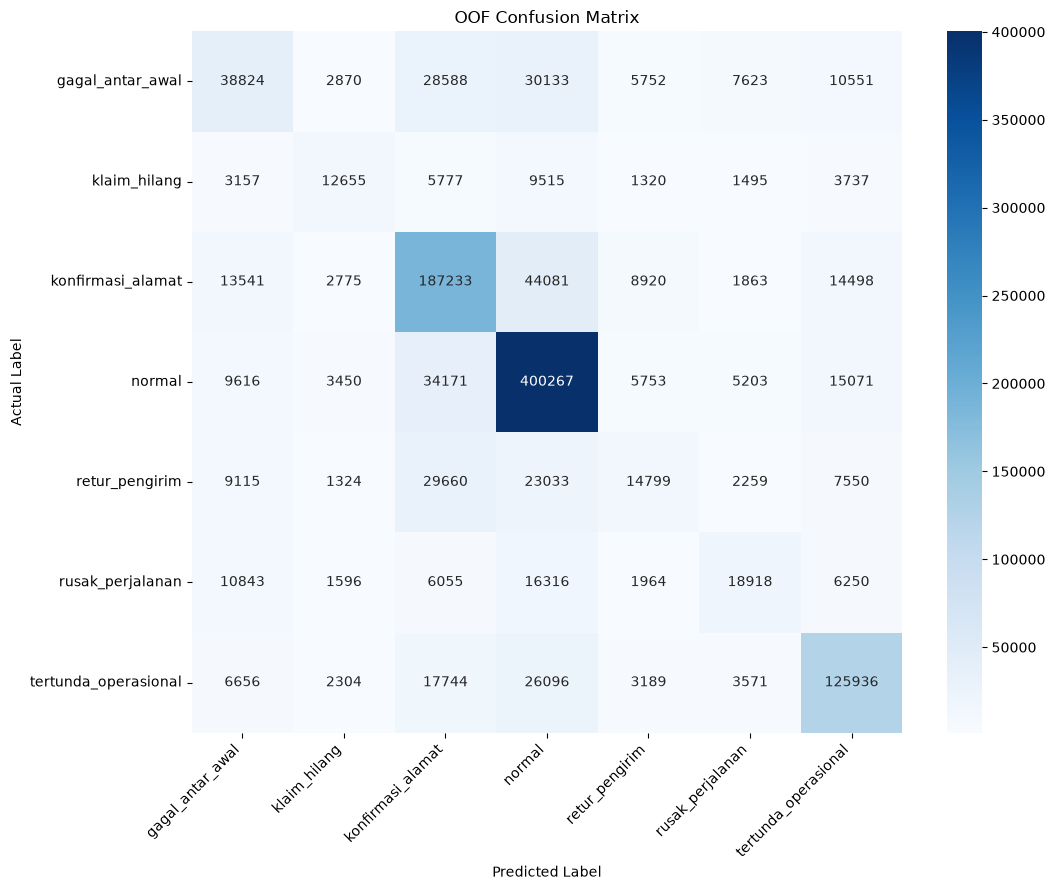

In [16]:
cm = confusion_matrix(
    y,
    oof_labels,
    labels=class_labels
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("OOF Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

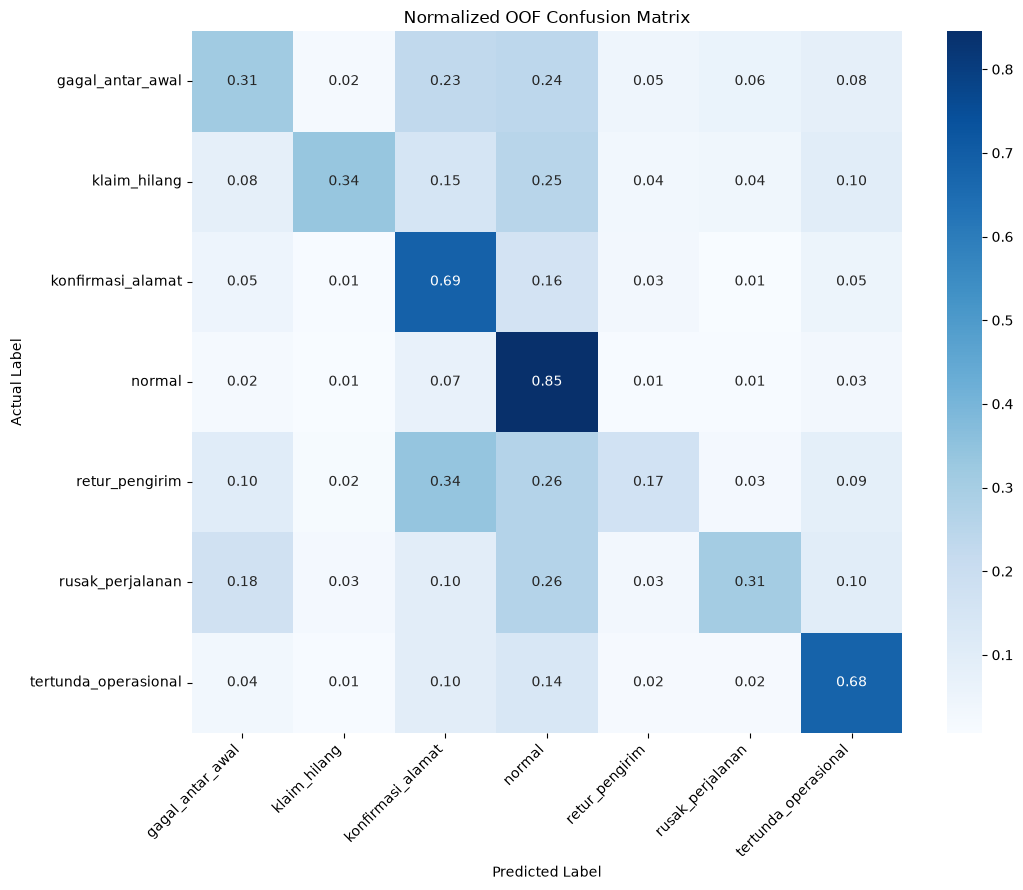

In [17]:
cm_normalized = cm / np.maximum(
    cm.sum(axis=1, keepdims=True),
    1
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Normalized OOF Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
feature_importance_all = pd.concat(
    feature_importance_frames,
    ignore_index=True
)

feature_importance_summary = (
    feature_importance_all
    .groupby("feature")
    .agg(
        mean_gain=("importance_gain", "mean"),
        std_gain=("importance_gain", "std"),
        mean_split=("importance_split", "mean"),
        std_split=("importance_split", "std")
    )
    .sort_values("mean_gain", ascending=False)
    .reset_index()
)

display(feature_importance_summary.head(40))

,feature,mean_gain,std_gain,mean_split,std_split
0,courier_id,4.510953e+06,64188.572208,55955.0,1351.250717
1,cust_address_quality,2.519484e+06,2656.635835,1390.8,5.585696
2,cour_hub_id,2.214335e+06,8741.116781,18353.6,241.644988
3,cust_complaint_index,1.408908e+06,2499.131999,2230.6,12.837445
4,cour_courier_score,8.358434e+05,2222.651650,1025.8,13.845577
5,cust_credit_score,7.162203e+05,709.894294,1578.4,13.831124
6,hub_density_index,6.002495e+05,5740.697010,121.2,3.492850
7,sc_quality_mean,4.397715e+05,2267.360951,507.4,7.368853
8,hub_id,3.267963e+05,4084.334707,3728.6,80.276398
9,declared_value,2.625772e+05,1000.944389,628.2,17.426991


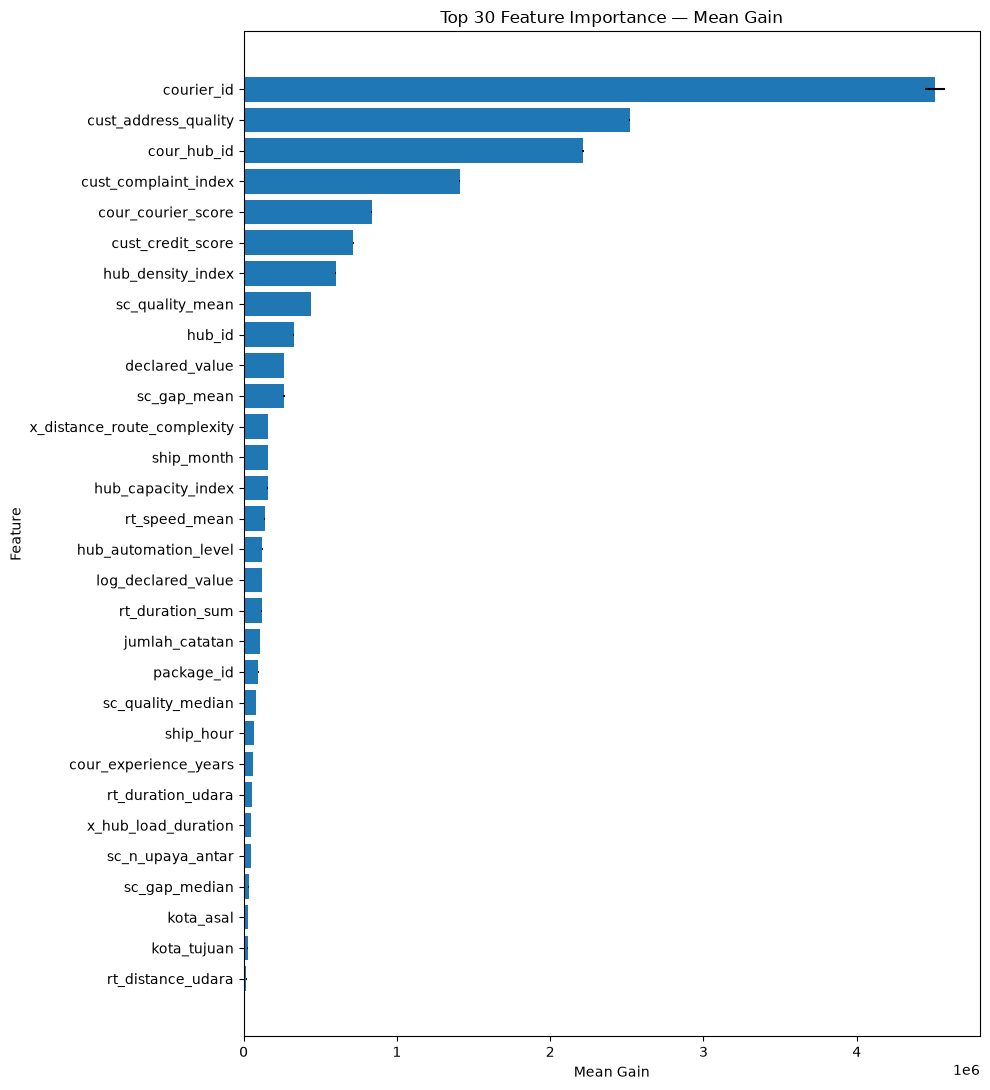

In [19]:
top_importance = feature_importance_summary.head(30).sort_values(
    "mean_gain",
    ascending=True
)

plt.figure(figsize=(10, 11))

plt.barh(
    top_importance["feature"],
    top_importance["mean_gain"],
    xerr=top_importance["std_gain"].fillna(0)
)

plt.title("Top 30 Feature Importance — Mean Gain")
plt.xlabel("Mean Gain")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [20]:
oof_error_analysis = train_df[[TARGET]].copy()

oof_error_analysis["predicted"] = oof_labels
oof_error_analysis["correct"] = (
    oof_error_analysis[TARGET] == oof_error_analysis["predicted"]
)

oof_error_analysis["confidence"] = oof_predictions.max(axis=1)

oof_error_analysis["actual_predicted"] = (
    oof_error_analysis[TARGET].astype(str)
    + " → "
    + oof_error_analysis["predicted"].astype(str)
)

error_summary = (
    oof_error_analysis[
        ~oof_error_analysis["correct"]
    ]
    .groupby("actual_predicted")
    .size()
    .sort_values(ascending=False)
    .head(30)
    .rename("jumlah_kesalahan")
    .to_frame()
)

display(error_summary)

,jumlah_kesalahan
actual_predicted,
konfirmasi_alamat → normal,44081
normal → konfirmasi_alamat,34171
gagal_antar_awal → normal,30133
retur_pengirim → konfirmasi_alamat,29660
gagal_antar_awal → konfirmasi_alamat,28588
tertunda_operasional → normal,26096
retur_pengirim → normal,23033
tertunda_operasional → konfirmasi_alamat,17744
rusak_perjalanan → normal,16316


In [21]:
class_f1 = classification_results.loc[
    class_labels,
    ["precision", "recall", "f1-score", "support"]
].copy()

class_f1.index.name = "class"

display(
    class_f1.sort_values(
        "f1-score",
        ascending=True
    )
)

,precision,recall,f1-score,support
class,,,,
retur_pengirim,0.354918,0.168669,0.228667,87740.0
gagal_antar_awal,0.423141,0.312238,0.359327,124341.0
rusak_perjalanan,0.462181,0.305415,0.367790,61942.0
klaim_hilang,0.469155,0.336069,0.391614,37656.0
konfirmasi_alamat,0.605485,0.686059,0.643259,272911.0
tertunda_operasional,0.685952,0.678915,0.682415,185496.0
normal,0.728499,0.845282,0.782557,473531.0


In [22]:
from sklearn.utils.class_weight import compute_class_weight

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array(class_labels),
    y=y
)

class_weight_dict = {
    label: float(weight)
    for label, weight in zip(class_labels, balanced_weights)
}

class_weight_table = pd.DataFrame({
    "class": class_labels,
    "count": [int((y == label).sum()) for label in class_labels],
    "weight": [class_weight_dict[label] for label in class_labels]
})

display(class_weight_table)

,class,count,weight
0,gagal_antar_awal,124341,1.428809
1,klaim_hilang,37656,4.717962
2,konfirmasi_alamat,272911,0.650980
3,normal,473531,0.375180
4,retur_pengirim,87740,2.024841
5,rusak_perjalanan,61942,2.868160
6,tertunda_operasional,185496,0.957754


In [25]:
RUN_BALANCED_CV = True

weighted_params = {
    **lgb_params,
    "class_weight": class_weight_dict
}

if RUN_BALANCED_CV:
    weighted_oof_predictions = np.zeros(
        (len(X), len(class_labels)),
        dtype=np.float32
    )

    weighted_fold_scores = []

    for fold, (train_idx, valid_idx) in enumerate(folds, start=1):
        print(f"\nTraining Balanced Fold {fold}/{N_SPLITS}")

        X_train_fold = X.iloc[train_idx]
        X_valid_fold = X.iloc[valid_idx]

        y_train_fold = y.iloc[train_idx]
        y_valid_fold = y.iloc[valid_idx]

        model = lgb.LGBMClassifier(**weighted_params)

        model.fit(
            X_train_fold,
            y_train_fold,
            eval_set=[(X_valid_fold, y_valid_fold)],
            eval_metric="multi_logloss",
            categorical_feature=categorical_features,
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=100,
                    verbose=False
                ),
                lgb.log_evaluation(period=200)
            ]
        )

        valid_probabilities = model.predict_proba(
            X_valid_fold,
            num_iteration=model.best_iteration_
        )

        model_classes = model.classes_.tolist()
        valid_probabilities = valid_probabilities[
            :,
            [model_classes.index(label) for label in class_labels]
        ]

        weighted_oof_predictions[valid_idx] = valid_probabilities

        valid_predictions = np.array(class_labels)[
            np.argmax(valid_probabilities, axis=1)
        ]

        fold_macro_f1 = f1_score(
            y_valid_fold,
            valid_predictions,
            average="macro"
        )

        weighted_fold_scores.append({
            "fold": fold,
            "macro_f1": fold_macro_f1,
            "best_iteration": model.best_iteration_
        })

        print(f"Fold {fold} Macro F1: {fold_macro_f1:.6f}")
        print(f"Best iteration: {model.best_iteration_}")

        del model, X_train_fold, X_valid_fold, y_train_fold, y_valid_fold
        gc.collect()

    weighted_fold_scores = pd.DataFrame(weighted_fold_scores)

    weighted_oof_labels = np.array(class_labels)[
        np.argmax(weighted_oof_predictions, axis=1)
    ]

    weighted_oof_f1 = f1_score(
        y,
        weighted_oof_labels,
        average="macro"
    )

    print("\nHasil per fold (Balanced):")
    display(weighted_fold_scores)
    print(f"Balanced OOF Macro F1: {weighted_oof_f1:.6f}")
    print(f"Baseline OOF Macro F1: {oof_macro_f1:.6f}")
else:
    # Fallback: pakai hasil baseline agar cell-cell berikutnya tetap jalan.
    weighted_oof_predictions = oof_predictions.copy()
    weighted_fold_scores = fold_scores.copy()
    weighted_oof_f1 = float("-inf")  # memastikan model baseline yang terpilih
    print("Balanced CV dilewati; model baseline akan dipakai.")


Training Balanced Fold 1/5
[200]	valid_0's multi_logloss: 1.14378
[400]	valid_0's multi_logloss: 1.12753
[600]	valid_0's multi_logloss: 1.1207
[800]	valid_0's multi_logloss: 1.11584
[1000]	valid_0's multi_logloss: 1.11192
[1200]	valid_0's multi_logloss: 1.10873
[1400]	valid_0's multi_logloss: 1.10649
[1600]	valid_0's multi_logloss: 1.10467
[1800]	valid_0's multi_logloss: 1.10364
[2000]	valid_0's multi_logloss: 1.10331
Fold 1 Macro F1: 0.495872
Best iteration: 2050

Training Balanced Fold 2/5
[200]	valid_0's multi_logloss: 1.14069
[400]	valid_0's multi_logloss: 1.1231
[600]	valid_0's multi_logloss: 1.11595
[800]	valid_0's multi_logloss: 1.11114
[1000]	valid_0's multi_logloss: 1.1066
[1200]	valid_0's multi_logloss: 1.10335
[1400]	valid_0's multi_logloss: 1.10053
[1600]	valid_0's multi_logloss: 1.09854
[1800]	valid_0's multi_logloss: 1.09745
[2000]	valid_0's multi_logloss: 1.0969


KeyboardInterrupt: 

In [24]:
model_comparison = pd.DataFrame([
    {
        "model": "LightGBM Baseline",
        "oof_macro_f1": oof_macro_f1,
        "mean_fold_macro_f1": fold_scores["macro_f1"].mean(),
        "std_fold_macro_f1": fold_scores["macro_f1"].std()
    },
    {
        "model": "LightGBM Balanced",
        "oof_macro_f1": weighted_oof_f1,
        "mean_fold_macro_f1": weighted_fold_scores["macro_f1"].mean(),
        "std_fold_macro_f1": weighted_fold_scores["macro_f1"].std()
    }
])

display(
    model_comparison.sort_values(
        "oof_macro_f1",
        ascending=False
    )
)

NameError: name 'weighted_oof_f1' is not defined

In [ ]:
def apply_class_multipliers(probabilities, multipliers):
    adjusted = probabilities * np.asarray(multipliers).reshape(1, -1)
    adjusted = adjusted / np.maximum(
        adjusted.sum(axis=1, keepdims=True),
        1e-12
    )
    return adjusted


def evaluate_multipliers(probabilities, targets, multipliers):
    adjusted = apply_class_multipliers(
        probabilities,
        multipliers
    )

    predictions = np.array(class_labels)[
        np.argmax(adjusted, axis=1)
    ]

    return f1_score(
        targets,
        predictions,
        average="macro"
    )

In [ ]:
def coordinate_search(
    probabilities,
    targets,
    initial_multipliers=None,
    candidate_values=None,
    max_rounds=3
):
    if initial_multipliers is None:
        multipliers = np.ones(len(class_labels), dtype=float)
    else:
        multipliers = np.array(
            initial_multipliers,
            dtype=float
        )

    if candidate_values is None:
        candidate_values = [
            0.70,
            0.80,
            0.90,
            1.00,
            1.10,
            1.20,
            1.30,
            1.50
        ]

    best_score = evaluate_multipliers(
        probabilities,
        targets,
        multipliers
    )

    history = []

    for round_number in range(max_rounds):
        improved = False

        for class_index, class_name in enumerate(class_labels):
            local_best_score = best_score
            local_best_multiplier = multipliers[class_index]

            for candidate in candidate_values:
                trial = multipliers.copy()
                trial[class_index] = candidate

                score = evaluate_multipliers(
                    probabilities,
                    targets,
                    trial
                )

                if score > local_best_score:
                    local_best_score = score
                    local_best_multiplier = candidate

            if local_best_score > best_score:
                multipliers[class_index] = local_best_multiplier
                best_score = local_best_score
                improved = True

            history.append({
                "round": round_number + 1,
                "class": class_name,
                "multiplier": multipliers[class_index],
                "macro_f1": best_score
            })

        if not improved:
            break

    return multipliers, best_score, pd.DataFrame(history)

In [ ]:
baseline_multipliers, baseline_tuned_f1, baseline_tuning_history = (
    coordinate_search(
        oof_predictions,
        y,
        max_rounds=3
    )
)

baseline_multiplier_table = pd.DataFrame({
    "class": class_labels,
    "multiplier": baseline_multipliers
})

print(f"Baseline OOF Macro F1: {oof_macro_f1:.6f}")
print(f"OOF Macro F1 setelah tuning: {baseline_tuned_f1:.6f}")

display(baseline_multiplier_table)
display(baseline_tuning_history)

In [ ]:
weighted_multipliers, weighted_tuned_f1, weighted_tuning_history = (
    coordinate_search(
        weighted_oof_predictions,
        y,
        max_rounds=3
    )
)

weighted_multiplier_table = pd.DataFrame({
    "class": class_labels,
    "multiplier": weighted_multipliers
})

print(f"Weighted OOF Macro F1: {weighted_oof_f1:.6f}")
print(f"Weighted OOF Macro F1 setelah tuning: {weighted_tuned_f1:.6f}")

display(weighted_multiplier_table)

In [ ]:
experiment_comparison = pd.DataFrame([
    {
        "experiment": "Baseline Argmax",
        "oof_macro_f1": oof_macro_f1
    },
    {
        "experiment": "Baseline + Multiplier",
        "oof_macro_f1": baseline_tuned_f1
    },
    {
        "experiment": "Balanced Argmax",
        "oof_macro_f1": weighted_oof_f1
    },
    {
        "experiment": "Balanced + Multiplier",
        "oof_macro_f1": weighted_tuned_f1
    }
])

display(
    experiment_comparison.sort_values(
        "oof_macro_f1",
        ascending=False
    )
)

In [ ]:
def run_scenario_cv(
    scenario_name,
    scenario_columns,
    n_estimators=3000
):
    scenario_columns = [
        col for col in scenario_columns
        if col in train_df.columns and col in test_df.columns
    ]

    scenario_columns = [
    col for col in scenario_columns
    if col not in high_cardinality_features
    ]

    scenario_X = train_df[scenario_columns].copy()
    scenario_y = train_df[TARGET].astype(str).copy()

    scenario_categorical = [
        col for col in scenario_columns
        if (
            not pd.api.types.is_numeric_dtype(scenario_X[col])
            or pd.api.types.is_object_dtype(scenario_X[col])
            or pd.api.types.is_bool_dtype(scenario_X[col])
            or isinstance(
                scenario_X[col].dtype,
                pd.CategoricalDtype
            )
        )
    ]

    scenario_test = test_df[scenario_columns].copy()

    for col in scenario_categorical:
        train_values = scenario_X[col].astype("string").fillna("__MISSING__")
        test_values = scenario_test[col].astype("string").fillna("__MISSING__")

        categories = pd.Index(
            pd.concat(
                [train_values, test_values],
                ignore_index=True
            ).unique()
        )

        scenario_X[col] = pd.Categorical(
            train_values,
            categories=categories
        )

        scenario_test[col] = pd.Categorical(
            test_values,
            categories=categories
        )

    scenario_X = scenario_X.replace([np.inf, -np.inf], np.nan)
    scenario_test = scenario_test.replace([np.inf, -np.inf], np.nan)

    scenario_oof = np.zeros(
        (len(scenario_X), len(class_labels)),
        dtype=np.float32
    )

    scenario_fold_scores = []

    params = {
        **lgb_params,
        "n_estimators": n_estimators
    }

    for fold, (train_idx, valid_idx) in enumerate(folds, start=1):
        model = lgb.LGBMClassifier(**params)

        model.fit(
            scenario_X.iloc[train_idx],
            scenario_y.iloc[train_idx],
            eval_set=[
                (
                    scenario_X.iloc[valid_idx],
                    scenario_y.iloc[valid_idx]
                )
            ],
            eval_metric="multi_logloss",
            categorical_feature=scenario_categorical,
            callbacks=[
                lgb.early_stopping(100, verbose=False),
                lgb.log_evaluation(0)
            ]
        )

        probabilities = model.predict_proba(
            scenario_X.iloc[valid_idx],
            num_iteration=model.best_iteration_
        )

        model_classes = model.classes_.tolist()

        probabilities = probabilities[
            :,
            [model_classes.index(label) for label in class_labels]
        ]

        scenario_oof[valid_idx] = probabilities

        predictions = np.array(class_labels)[
            np.argmax(probabilities, axis=1)
        ]

        score = f1_score(
            scenario_y.iloc[valid_idx],
            predictions,
            average="macro"
        )

        scenario_fold_scores.append(score)

        del model
        gc.collect()

    scenario_predictions = np.array(class_labels)[
        np.argmax(scenario_oof, axis=1)
    ]

    return {
        "scenario": scenario_name,
        "n_features": len(scenario_columns),
        "oof_macro_f1": f1_score(
            scenario_y,
            scenario_predictions,
            average="macro"
        ),
        "mean_fold_macro_f1": np.mean(scenario_fold_scores),
        "std_fold_macro_f1": np.std(scenario_fold_scores),
        "oof_predictions": scenario_oof
    }

In [ ]:
RUN_SCENARIO_COMPARISON = False

scenario_results = []

if RUN_SCENARIO_COMPARISON:
    for scenario_name in ["A", "B", "C"]:
        print(f"\nMenjalankan skenario {scenario_name}")

        result = run_scenario_cv(
            scenario_name,
            scenario_features[scenario_name]
        )

        scenario_results.append({
            key: value
            for key, value in result.items()
            if key != "oof_predictions"
        })

        print(
            f"Skenario {scenario_name}: "
            f"Macro F1 = {result['oof_macro_f1']:.6f}"
        )

    scenario_results = pd.DataFrame(scenario_results)
    display(scenario_results)
else:
    print("Perbandingan skenario belum dijalankan.")

In [ ]:
USE_BALANCED_MODEL = weighted_oof_f1 > oof_macro_f1
APPLY_CLASS_MULTIPLIERS = False

if USE_BALANCED_MODEL:
    final_class_weights = class_weight_dict
    final_oof_predictions = weighted_oof_predictions
    final_oof_score = weighted_oof_f1
    selected_model_name = "LightGBM Balanced"
else:
    final_class_weights = None
    final_oof_predictions = oof_predictions
    final_oof_score = oof_macro_f1
    selected_model_name = "LightGBM Baseline"

if APPLY_CLASS_MULTIPLIERS:
    if USE_BALANCED_MODEL:
        final_multipliers = weighted_multipliers
    else:
        final_multipliers = baseline_multipliers
else:
    final_multipliers = np.ones(len(class_labels))

print(f"Model terpilih: {selected_model_name}")
print(f"OOF Macro F1: {final_oof_score:.6f}")
print(f"Class multiplier digunakan: {APPLY_CLASS_MULTIPLIERS}")

In [ ]:
if USE_BALANCED_MODEL:
    selected_iterations = weighted_fold_scores["best_iteration"].values
else:
    selected_iterations = fold_scores["best_iteration"].values

final_n_estimators = max(
    100,
    int(np.median(selected_iterations))
)

print(f"Final n_estimators: {final_n_estimators}")

In [ ]:
final_params = {
    **lgb_params,
    "n_estimators": final_n_estimators
}

if final_class_weights is not None:
    final_params["class_weight"] = final_class_weights

final_model = lgb.LGBMClassifier(
    **final_params
)

final_model.fit(
    X,
    y,
    categorical_feature=categorical_features
)

print("Training final model selesai.")
print(f"Jumlah estimators: {final_model.n_estimators_}")

In [ ]:
test_probabilities = final_model.predict_proba(X_test)

final_model_classes = final_model.classes_.tolist()

test_probabilities = test_probabilities[
    :,
    [final_model_classes.index(label) for label in class_labels]
]

test_probabilities_adjusted = apply_class_multipliers(
    test_probabilities,
    final_multipliers
)

test_predictions = np.array(class_labels)[
    np.argmax(test_probabilities_adjusted, axis=1)
]

test_prediction_distribution = (
    pd.Series(test_predictions)
    .value_counts()
    .reindex(class_labels, fill_value=0)
    .rename_axis(TARGET)
    .to_frame("jumlah_prediksi")
)

test_prediction_distribution["persentase"] = (
    test_prediction_distribution["jumlah_prediksi"]
    / len(test_predictions)
    * 100
)

display(test_prediction_distribution)

In [ ]:
train_distribution = (
    y.value_counts(normalize=True)
    .reindex(class_labels, fill_value=0)
)

test_distribution = (
    pd.Series(test_predictions)
    .value_counts(normalize=True)
    .reindex(class_labels, fill_value=0)
)

distribution_comparison = pd.DataFrame({
    "train": train_distribution,
    "test_prediction": test_distribution
})

distribution_comparison["difference"] = (
    distribution_comparison["test_prediction"]
    - distribution_comparison["train"]
)

display(
    distribution_comparison.style.format("{:.4%}")
)

In [ ]:
distribution_comparison[
    ["train", "test_prediction"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Distribusi Target Train vs Prediksi Test")
plt.xlabel("Status Penanganan")
plt.ylabel("Proporsi")
plt.xticks(rotation=45, ha="right")
plt.legend(["Train", "Test Prediction"])
plt.tight_layout()
plt.show()

In [ ]:
submission_path = Path("submission.csv")
from analysis_data import DATA_DIR
sample_submission_path = DATA_DIR / "sample_submission.csv"

if sample_submission_path.exists():
    sample_submission = pd.read_csv(sample_submission_path)

    submission = sample_submission.copy()

    if TARGET not in submission.columns:
        raise ValueError(
            f"Kolom target {TARGET} tidak ditemukan pada sample submission."
        )

    if len(submission) != len(test_predictions):
        raise ValueError(
            "Jumlah baris test tidak sama dengan jumlah baris sample submission."
        )

    if id_column is not None and id_column in submission.columns:
        # Petakan prediksi berdasarkan ID agar urutan selalu cocok dengan sample submission
        prediction_map = pd.Series(test_predictions, index=test_ids.values)
        submission[TARGET] = submission[id_column].map(prediction_map)

        if submission[TARGET].isna().any():
            raise ValueError("Ada ID sample submission yang tidak punya prediksi.")
    else:
        submission[TARGET] = test_predictions

else:
    if id_column is None:
        submission = pd.DataFrame({
            TARGET: test_predictions
        })
    else:
        submission = pd.DataFrame({
            id_column: test_ids.values,
            TARGET: test_predictions
        })

submission.to_csv(
    submission_path,
    index=False
)

print(f"Submission tersimpan: {submission_path.resolve()}")
display(submission.head())
print(f"Submission shape: {submission.shape}")

In [ ]:
submission_check = pd.read_csv(submission_path)

assert len(submission_check) == len(test_df)
assert TARGET in submission_check.columns
assert submission_check[TARGET].notna().all()
assert set(submission_check[TARGET].unique()).issubset(
    set(class_labels)
)

if id_column is not None and id_column in submission_check.columns:
    assert submission_check[id_column].is_unique

print("Submission lolos pemeriksaan dasar.")
print("Jumlah baris:", len(submission_check))
print("Jumlah prediksi kosong:", submission_check[TARGET].isna().sum())
print("Kelas prediksi:", sorted(submission_check[TARGET].unique()))

In [ ]:
import joblib

output_dir = Path("notebook20_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    final_model,
    output_dir / "lightgbm_final.pkl"
)

fold_scores.to_csv(
    output_dir / "baseline_fold_scores.csv",
    index=False
)

weighted_fold_scores.to_csv(
    output_dir / "weighted_fold_scores.csv",
    index=False
)

classification_results.to_csv(
    output_dir / "classification_report.csv"
)

feature_importance_summary.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

model_comparison.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

experiment_comparison.to_csv(
    output_dir / "multiplier_experiment_comparison.csv",
    index=False
)

baseline_multiplier_table.to_csv(
    output_dir / "baseline_multipliers.csv",
    index=False
)

weighted_multiplier_table.to_csv(
    output_dir / "weighted_multipliers.csv",
    index=False
)

with open(
    output_dir / "model_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        {
            "model": selected_model_name,
            "scenario": SELECTED_SCENARIO,
            "target": TARGET,
            "classes": class_labels,
            "features": selected_features,
            "n_features": len(selected_features),
            "n_estimators": final_n_estimators,
            "n_splits": N_SPLITS,
            "random_state": RANDOM_STATE,
            "oof_macro_f1": float(final_oof_score),
            "class_multipliers_applied": APPLY_CLASS_MULTIPLIERS
        },
        file,
        ensure_ascii=False,
        indent=4
    )

print(f"Artefak eksperimen tersimpan di {output_dir.resolve()}")